# TP3 - projet EDA : Analyse exploratoire de données

## Membres de l'équipe

> Complétez cette section avant de commencer le travail.

| Membre | Nom | Prénom | Numéro DA |
|---|---|---|---|
| Étudiant(e) 1 | Nguyen | Ta Anh Quoc | 2075009 |
| Étudiant(e) 2 | Frédérick | Forget | 2389013 |
| Étudiant(e) 3 | Cedric | Champoux | 2292170 |

**Équipe :**  
**Groupe :**  
**Date de remise :**


## Répartition des responsabilités

| Membre | Responsabilités principales |
|---|---|
| Étudiant(e) 1 | La creation des graphes |
| Étudiant(e) 2 | Analyse des données brutes |
| Étudiant(e) 3 | Groupement et filtres |

> Le notebook doit former une analyse cohérente. La répartition du travail ne doit pas produire plusieurs analyses indépendantes.


## 0. Dictionnaire des données
| Colonne | Description |
|---|---|
| timestamp      | Date et heure de la mesure |
| building       | Bâtiment |
| room           | Local |
| room_type      | Type de local |
| capacity       | Capacité |
| occupancy      | Nombre d'occupants |
| temperature    | Température intérieure (°C) |
| humidity       | Humidité relative (%) |
| co2_ppm        | Concentration de CO₂ (ppm) |
| power_kw       | Consommation électrique (kW) |
| outdoor_temp   | Température extérieure (°C) |
| is_weekend     | Mesure prise durant la fin de semaine |

## 1. Présentation du problème

À partir du contexte général fourni et après une première exploration du jeu de données, l’équipe doit **formuler une problématique d’analyse claire**.
La problématique doit :
- être liée aux données disponibles ;
- être suffisamment précise pour guider l’analyse ;
- pouvoir être étudiée avec les variables du jeu de données ;
- mener à des constats utiles pour l’organisation.

Voici quelques exemples de pistes, vous n'êtes pas obligés de choisir dans cette liste :
- Comment réduire la consommation énergétique inutile dans les bâtiments ?
- Quels locaux présentent des comportements de consommation inhabituels ?
- Dans quelle mesure l’occupation influence-t-elle la consommation ?
- Existe-t-il des périodes où l’énergie semble être consommée inefficacement ?
- Quels bâtiments devraient être priorisés pour une analyse énergétique plus approfondie ?

À partir de votre problématique définisseez **2 à 4 questions d’analyse directement liées à votre problématique** en plus des 6 déjà présentés dans la section 10.

**Exemples de questions d’analyse :**
1. Quels bâtiments ont la consommation moyenne la plus élevée ?
2. Quels locaux consomment beaucoup malgré une faible occupation ?
3. À quelles heures ces comportements apparaissent-ils ?

**Présentez brièvement :**

- le contexte du jeu de données ;
- l'objectif de l'analyse ;
- les principales questions auxquelles l'équipe souhaite répondre (2 à 4 questions).


## Problématique:
Comment réduire la consommation énergétique inutile dans les bâtiments ?
## Questions d'analyses:
• Quelles heures ont les consommations les plus élevées?
• Quels locaux consomment beaucoup malgré une faible occupation ?  

## 2. Importation des bibliothèques

Utilisez principalement **NumPy**, **Pandas**, **Matplotlib** et **ipywidgets**.


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ipywidgets import interact

## 3. Chargement des données

Chargez le jeu de données fourni dans un `DataFrame` Pandas.

Affichez quelques observations afin de vérifier que le chargement s'est correctement effectué.


In [14]:
df = pd.read_csv('campus_energy.csv')
print(f"columns: {df.columns.to_list()}")
print(f"rows: {df.size}")

columns: ['timestamp', 'building', 'room', 'room_type', 'capacity', 'occupancy', 'temperature', 'humidity', 'co2_ppm', 'power_kw', 'outdoor_temp', 'is_weekend']
rows: 258384


## 4. Compréhension du jeu de données

Déterminez notamment :

- le nombre d'observations ;
- le nombre de variables ;
- le nom des colonnes ;
- le type des variables ;
- les variables numériques ;
- les variables catégorielles ;
- la présence de valeurs manquantes ;
- la présence éventuelle de données incohérentes.


In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21532 entries, 0 to 21531
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   timestamp     21532 non-null  str    
 1   building      21532 non-null  str    
 2   room          21532 non-null  str    
 3   room_type     21532 non-null  str    
 4   capacity      21532 non-null  int64  
 5   occupancy     21492 non-null  float64
 6   temperature   21442 non-null  float64
 7   humidity      21457 non-null  float64
 8   co2_ppm       21447 non-null  float64
 9   power_kw      21472 non-null  float64
 10  outdoor_temp  21532 non-null  float64
 11  is_weekend    21532 non-null  bool   
dtypes: bool(1), float64(6), int64(1), str(4)
memory usage: 1.8 MB


In [16]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
capacity,21532.0,25.871819,10.845802,8.00,12.00,28.00,32.00,45.00
occupancy,21492.0,4.797506,6.308226,0.00,0.00,2.00,7.00,46.00
temperature,21442.0,21.224727,0.990015,4.50,20.57,21.39,21.92,39.00
humidity,21457.0,42.768607,3.191149,29.20,40.60,42.70,44.90,55.80
co2_ppm,21447.0,538.937008,156.218488,350.00,436.00,487.00,590.00,3306.00
power_kw,21472.0,2.939193,1.258820,0.23,2.00,2.87,3.73,27.91
outdoor_temp,21532.0,10.418534,4.288918,0.53,6.53,10.40,14.30,20.97


In [17]:
cols = df.columns.to_list()
print("unique occurance:", "\n".join([f"{c}: {df.__getattr__(c).value_counts().to_list().__len__()}" for c in cols]), sep="\n")
del cols

unique occurance:
timestamp: 1344
building: 4
room: 16
room_type: 4
capacity: 14
occupancy: 35
temperature: 514
humidity: 225
co2_ppm: 704
power_kw: 607
outdoor_temp: 1741
is_weekend: 2


In [18]:
cols = df.columns.to_list()
print("missing values:", "\n".join([f"{c}: {df.__getattr__(c).isna().to_list().count(True)}" for c in cols]), sep="\n")
del cols

missing values:
timestamp: 0
building: 0
room: 0
room_type: 0
capacity: 0
occupancy: 40
temperature: 90
humidity: 75
co2_ppm: 85
power_kw: 60
outdoor_temp: 0
is_weekend: 0


### Premières observations

Rédigez ici un court paragraphe présentant les principaux constats issus de cette première exploration.


## 5. Nettoyage et préparation des données

Vérifiez notamment :

- les valeurs manquantes ;
- les doublons ;
- les types de données ;
- les valeurs impossibles ou incohérentes.

Pour chaque traitement important, expliquez :

1. le problème identifié ;
2. la décision prise ;
3. la raison de cette décision.

In [19]:
df_clean = df.copy()

In [20]:
# --- Valeurs manquantes ---

occupancy_par_defaut = df_clean.occupancy.value_counts()[0]
# indique que la valeur de 0.0 devrait être la valeur par défaut.

temperature_moyenne = df_clean.temperature.mean()
# utilisation de la moyenne afin de ne pas trops bouger les statistiques

humidite_moyenne = df_clean.humidity.mean()
# utilisation de la moyenne afin de ne pas trops bouger les statistiques

co2_ppm_moyen = df_clean.co2_ppm.mean()
# utilisation de la moyenne afin de ne pas trops bouger les statistiques

# la distribution de power_kw n'est pas centré. La medianne sera donc utilisé
power_kw_median = df_clean.power_kw.median()


df_clean.occupancy = df_clean.occupancy.fillna(occupancy_par_defaut)
df_clean.temperature = df_clean.temperature.fillna(temperature_moyenne)
df_clean.humidity = df_clean.humidity.fillna(humidite_moyenne)
df_clean.co2_ppm = df_clean.co2_ppm.fillna(co2_ppm_moyen)
df_clean.power_kw = df_clean.power_kw.fillna(power_kw_median)

In [21]:
# Doublons
df_clean.drop_duplicates(inplace=True, ignore_index=True)

/tmp/ipykernel_162441/4213738667.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_clean.drop_duplicates(inplace=True, ignore_index=True)


In [22]:
# Conversion des types et autres nettoyages


### Justification des traitements

Expliquez ici les principales décisions prises pendant le nettoyage des données.


## 6. Création de nouvelles variables

Créez **au moins 3 nouvelles variables** pertinentes pour l'analyse.

Exemples possibles :

- heure ;
- jour ;
- période de la journée ;
- taux d'occupation ;
- consommation par occupant ;
- toute autre variable dérivée utile.

Expliquez pour chaque variable :

- comment elle est calculée ;
- pourquoi elle est utile.


In [23]:
# Heure, Jour, Période de la journée, étage
from datetime import datetime

heures = []
jours = []
timeofdays = []
for _time in df_clean.timestamp:
    try:
        dt = datetime.strptime(_time, "%Y-%m-%d %H:%M:%S")
        heures += [dt.hour]
        jours += [dt.day]
        match dt.hour:
            case 24 | 0 | 1 | 2 | 3 | 4:
                _day_period = "night"
            case 5 | 6 | 7 | 8 | 9 | 10 | 11: 
                _day_period = "morning"
            case 12 | 13: 
                _day_period = "noon"
            case 14 | 15 | 16: 
                _day_period = "afternoon"
            case 17 | 18 | 19 | 20 | 21: 
                _day_period = "evening"
            case 22 | 23: 
                _day_period = "night"
            case _:
                _day_period = "night"
        timeofdays += [_day_period]
    except:
        print(_time)
additional_df = pd.DataFrame(data={"timeofday": timeofdays, "day": jours, "hour": heures})
del heures, jours, timeofdays

additional_df["floor"] = pd.to_numeric(df_clean["room"].str[1:2])

print(additional_df.info())

<class 'pandas.DataFrame'>
RangeIndex: 21504 entries, 0 to 21503
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   timeofday  21504 non-null  str  
 1   day        21504 non-null  int64
 2   hour       21504 non-null  int64
 3   floor      21504 non-null  int64
dtypes: int64(3), str(1)
memory usage: 672.1 KB
None


### Sauvegarde des données nettoyées
Une fois le nettoyage terminé, sauvegardez le jeu de données nettoyé dans un **nouveau fichier** portant le nom `donnees_nettoyees.csv`.

Le fichier original ne doit pas être modifié ou écrasé.

Le fichier nettoyé doit être remis avec le notebook.

In [24]:
# Sauvegarde du jeu de données nettoyé

df = df_clean.join(additional_df)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21504 entries, 0 to 21503
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   timestamp     21504 non-null  str    
 1   building      21504 non-null  str    
 2   room          21504 non-null  str    
 3   room_type     21504 non-null  str    
 4   capacity      21504 non-null  int64  
 5   occupancy     21504 non-null  float64
 6   temperature   21504 non-null  float64
 7   humidity      21504 non-null  float64
 8   co2_ppm       21504 non-null  float64
 9   power_kw      21504 non-null  float64
 10  outdoor_temp  21504 non-null  float64
 11  is_weekend    21504 non-null  bool   
 12  timeofday     21504 non-null  str    
 13  day           21504 non-null  int64  
 14  hour          21504 non-null  int64  
 15  floor         21504 non-null  int64  
dtypes: bool(1), float64(6), int64(4), str(5)
memory usage: 2.5 MB


### Justification des nouvelles variables

Expliquez ici l'intérêt des variables créées.


## 7. Statistiques descriptives

Calculez plusieurs statistiques pertinentes :

- moyenne ;
- médiane ;
- minimum ;
- maximum ;
- écart-type ;
- variance ;
- quartiles.

Utilisez **NumPy et/ou Pandas**.


In [25]:
# Statistiques descriptives

df.describe()

,capacity,occupancy,temperature,humidity,co2_ppm,power_kw,outdoor_temp,day,hour,floor
count,21504.000000,21504.000000,21504.000000,21504.000000,21504.000000,21504.000000,21504.000000,21504.000000,21504.000000,21504.000000
mean,25.875000,17.260463,21.224478,42.768236,538.905861,2.938072,10.419508,14.500000,11.500000,1.500000
std,10.845038,288.823442,0.988246,3.185689,155.899221,1.249728,4.289163,8.077935,6.922348,0.500012
min,8.000000,0.000000,4.500000,29.200000,350.000000,0.230000,0.530000,1.000000,0.000000,1.000000
25%,19.500000,0.000000,20.570000,40.600000,436.000000,2.000000,6.530000,7.750000,5.750000,1.000000
50%,28.000000,2.000000,21.390000,42.700000,488.000000,2.870000,10.400000,14.500000,11.500000,1.500000
75%,32.500000,7.000000,21.920000,44.900000,589.000000,3.730000,14.300000,21.250000,17.250000,2.000000
max,45.000000,6706.000000,39.000000,55.800000,3306.000000,27.910000,20.970000,28.000000,23.000000,2.000000


In [26]:
numerical_df = df.select_dtypes(include=np.number)
print(numerical_df.median()
      .rename("Median")
      .rename_axis("Column")
      .reset_index())
print(numerical_df.var()
      .rename("Variance")
      .rename_axis("Column")
      .reset_index())

         Column  Median
0      capacity   28.00
1     occupancy    2.00
2   temperature   21.39
3      humidity   42.70
4       co2_ppm  488.00
5      power_kw    2.87
6  outdoor_temp   10.40
7           day   14.50
8          hour   11.50
9         floor    1.50
         Column      Variance
0      capacity    117.614844
1     occupancy  83418.980614
2   temperature      0.976629
3      humidity     10.148616
4       co2_ppm  24304.567212
5      power_kw      1.561820
6  outdoor_temp     18.396923
7           day     65.253034
8          hour     47.918895
9         floor      0.250012


### Interprétation

Interprétez les résultats statistiques les plus importants.
1. La variance 
2. min : certaines donnees ont une occupation de 0, qui peuvent indiquer un moment de la journee au l'usage pourrait etre reduit. 
3. mean : la moyenne de consomption d'energie nous donne une idee de la depense actuelle d'energie dans chaque donnees.

## 8. Analyse par groupes

Effectuez au moins **2 analyses avec `groupby()`**.

Exemples :

- consommation moyenne par bâtiment ;
- statistiques par local ;
- comparaison par jour ;
- comparaison par période.


In [27]:
# Creer la variable necessaire
df["hour"] = pd.to_datetime(df["timestamp"], format="%Y-%m-%d %H:%M:%S").dt.hour

In [28]:
# Groupby 1
# avg Consommations par heures:


print(df.groupby(["hour"])["power_kw"].mean())

hour
0     2.863862
1     2.830067
2     2.890558
3     2.892567
4     2.973281
5     3.001317
6     2.648806
7     2.664252
8     3.206060
9     3.219978
10    3.208817
11    3.162377
12    2.951897
13    2.870703
14    3.132946
15    3.175368
16    3.101585
17    3.166250
18    2.716819
19    2.718415
20    2.709487
21    2.602478
22    2.891942
23    2.913884
Name: power_kw, dtype: float64


In [29]:
# Groupby 2
#avg occupation par heure
print(df.groupby(["hour"])["occupancy"].mean())

hour
0      1.264509
1      1.198661
2      1.101562
3     46.097098
4      8.636161
5     16.101562
6     23.641741
7      8.635045
8     24.472098
9     17.022321
10     9.551339
11    46.901786
12    13.779018
13    21.149554
14    25.340402
15    25.328125
16    17.729911
17    32.676339
18    10.978795
19    18.391741
20    18.250000
21     1.217634
22     8.609375
23    16.176339
Name: occupancy, dtype: float64


In [30]:
# heure moin occuper par batiment
df_group = df.groupby(["building","hour"])["occupancy"].sum().reset_index()
df_group.loc[
    df_group.groupby("building")["occupancy"].idxmin()
]


,building,hour,occupancy
2,A,2,186.0
30,B,6,270.0
49,C,1,215.0
76,D,4,251.0


### Interprétation

Expliquez les différences ou tendances observées entre les groupes.


L'occupation des batiments on tendances a diminuer vers le soir a partir de 18h et augmenter a 9h.

## 9. Filtrage des données

Présentez au moins **3 filtrages booléens pertinents**.

Chaque filtre doit répondre à une question d'analyse.


In [31]:
# Filtre 1
# quelles heures consomment plus que la moyenne
df_group = df.groupby(["hour"])
mean_powerkw = df_group["power_kw"].sum().mean()
print("mean", ":", mean_powerkw)
df_bool = df_group["power_kw"].sum() > mean_powerkw
print(df_group["power_kw"].sum()[df_bool].reset_index())


mean : 2632.5120833333335
    hour  power_kw
0      4   2664.06
1      5   2689.18
2      8   2872.63
3      9   2885.10
4     10   2875.10
5     11   2833.49
6     12   2644.90
7     14   2807.12
8     15   2845.13
9     16   2779.02
10    17   2836.96


In [32]:
# Filtre 2

# quelles locaux sont moin occuper que la moyenne
df_group = df.groupby(["room"])
mean_occupancy = df_group["occupancy"].sum().mean()
print("mean", ":", mean_occupancy)
df_bool = df_group["occupancy"].sum() < mean_occupancy
print(df_group["occupancy"].sum()[df_bool].reset_index())


mean : 23198.0625
   room  occupancy
0  A101    22068.0
1  A201     5941.0
2  A202    22119.0
3  B102    22500.0
4  B202    22376.0
5  C201    15091.0
6  C202    22630.0
7  D101    21563.0
8  D102    13761.0
9  D201     8578.0


In [33]:
# Filtre 3
# La salle dont la consommation est plus grande que la moyenne
df_group = df.groupby(["room"])
mean_powerkw = df_group["power_kw"].sum().mean()
print("mean", ":", mean_powerkw)
df_bool = df_group["power_kw"].sum() > mean_powerkw
print(df_group["power_kw"].sum()[df_bool].reset_index())


mean : 3948.7681249999996
   room  power_kw
0  A201   5031.21
1  B101   4750.20
2  B201   6180.16
3  B202   4863.77
4  C102   4895.19
5  D102   6050.79
6  D202   4498.05


In [34]:
# La salle dont l'occupation est plus basse que la moyenne, mais la consommation est plus haute que la moyenne.
df_group = df.groupby(["room"])
mean_occupancy = df_group["occupancy"].sum().mean()
print("occupancy", "mean", ":", mean_occupancy)
df_bool = df_group["occupancy"].sum() < mean_occupancy
df_result = df_group["occupancy"].sum()[df_bool].reset_index()

df_group2 = df.groupby(["room"])
mean_powerkw = df_group2["power_kw"].sum().mean()
print("power_kw","mean", ":", mean_powerkw)
df_bool2 = df_group2["power_kw"].sum() > mean_powerkw
df_result2 = df_group2["power_kw"].sum()[df_bool2].reset_index()

pd.merge(df_result,df_result2, how='inner', on="room")

occupancy mean : 23198.0625
power_kw mean : 3948.7681249999996


,room,occupancy,power_kw
0,A201,5941.0,5031.21
1,B202,22376.0,4863.77
2,D102,13761.0,6050.79


### Interprétation

Expliquez ce que ces sous-ensembles permettent d'observer.


## 10. Valeurs atypiques

Utilisez une méthode statistique simple pour identifier certaines observations atypiques.

Une méthode possible consiste à utiliser l'écart interquartile :

$$
IQR = Q_3 - Q_1
$$

$$
Borne_{inf} = Q_1 - 1.5 \times IQR
$$

$$
Borne_{sup} = Q_3 + 1.5 \times IQR
$$


In [35]:
# Detection des valeurs atypiques avec l'ecart interquartile (IQR)
def bornes_iqr(colonne):
    q1 = df[colonne].quantile(0.25)
    q3 = df[colonne].quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

for col in ["occupancy", "temperature", "humidity", "co2_ppm", "power_kw"]:
    borne_inf, borne_sup = bornes_iqr(col)
    nb = ((df[col] < borne_inf) | (df[col] > borne_sup)).sum()
    print(f"{col} : bornes [{borne_inf:.2f} ; {borne_sup:.2f}] -> {nb} valeurs atypiques")

# Pics de consommation
borne_inf_power, borne_sup_power = bornes_iqr("power_kw")
atypiques_power = df[df["power_kw"] > borne_sup_power]
print("\nLocaux avec le plus de pics :", atypiques_power["room"].value_counts().head(3).to_dict())
print(atypiques_power[["timestamp", "room", "occupancy", "power_kw"]].sort_values("power_kw", ascending=False).head(10))


occupancy : bornes [-10.50 ; 17.50] -> 1579 valeurs atypiques
temperature : bornes [18.54 ; 23.95] -> 27 valeurs atypiques
humidity : bornes [34.15 ; 51.35] -> 158 valeurs atypiques
co2_ppm : bornes [206.50 ; 818.50] -> 1600 valeurs atypiques
power_kw : bornes [-0.59 ; 6.32] -> 36 valeurs atypiques

Locaux avec le plus de pics : {'D102': 11, 'C201': 5, 'B101': 3}
                 timestamp  room  occupancy  power_kw
5317   2026-10-21 21:00:00  D102        2.0     27.91
7511   2026-10-12 14:00:00  B101       24.0     27.72
19748  2026-10-15 23:00:00  B102        1.0     27.05
8522   2026-10-12 02:00:00  C201        0.0     25.02
15953  2026-10-23 12:00:00  A202        3.0     23.99
15997  2026-10-28 02:00:00  C202        0.0     23.40
10396  2026-10-19 15:30:00  D201        4.0     22.85
18672  2026-10-03 17:00:00  A102        0.0     21.99
18943  2026-10-09 15:30:00  A202        2.0     21.55
13930  2026-10-26 17:30:00  B101       22.0     21.49


### Analyse des valeurs atypiques

Répondez notamment aux questions suivantes :

- Combien d'observations sont détectées ?
    - occupancy : 1579 valeurs
    - temperature : 27 valeurs
    - humidity : 158 valeurs
    - co2_ppm : 1600 valeurs
    - power_kw : 36 valeurs
    
- À quoi correspondent-elles ?
    - Occupancy : les valeurs qui correspondent à des chambres qui ne sont pas occupées ou occupées entre certaines heures.
    - Temperature : la température dans une chambre. Si c'est le matin, les chambres sont plus chaudes, si c’est le soir, c'est plus froid.
    - Humidity : L'humidité d'une chambre a certaines heures dans la journée.
    - Co2_ppm : L'air co2 produit quand les chambres sont occupées ou pas.
    - Power_kw : L'électricité utilisée pendant les heures de la journée.
- S'agit-il nécessairement d'erreurs ?
  - Non. Pour occupancy, co2_ppm et humidity, la méthode IQR détecte surtout des situations normales (salles pleines) puisque les locaux sont vides une grande partie du temps : les distributions sont asymétriques


## 11. Corrélation

Analysez les relations entre plusieurs variables numériques.

Calculez une matrice de corrélation et identifiez au moins une relation intéressante.


              capacity  occupancy  temperature  humidity  co2_ppm  power_kw  \
capacity          1.00       0.33         0.05      0.11     0.29      0.43   
occupancy         0.33       1.00         0.36      0.32     0.89      0.37   
temperature       0.05       0.36         1.00      0.02     0.32      0.12   
humidity          0.11       0.32         0.02      1.00     0.28      0.12   
co2_ppm           0.29       0.89         0.32      0.28     1.00      0.34   
power_kw          0.43       0.37         0.12      0.12     0.34      1.00   
outdoor_temp     -0.00      -0.09         0.33     -0.08    -0.08     -0.06   

              outdoor_temp  
capacity             -0.00  
occupancy            -0.09  
temperature           0.33  
humidity             -0.08  
co2_ppm              -0.08  
power_kw             -0.06  
outdoor_temp          1.00  


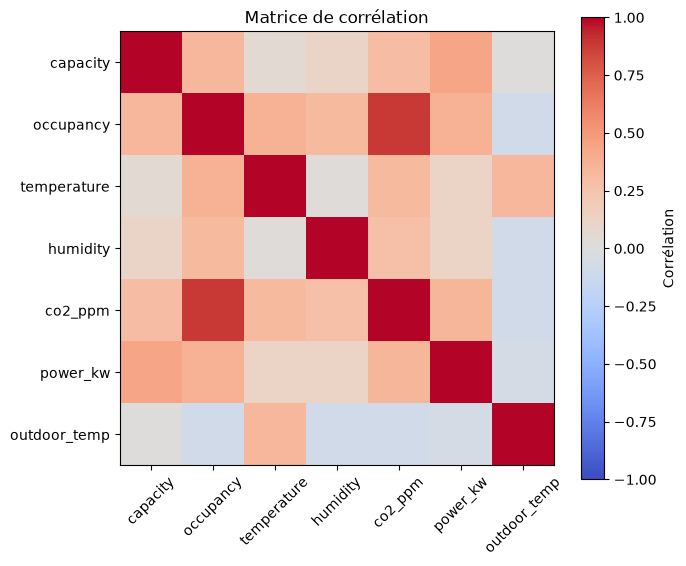

In [36]:
# Corrélations
df_valid = df[df["occupancy"] <= df["capacity"]]

colonnes = ["capacity", "occupancy", "temperature", "humidity", "co2_ppm", "power_kw", "outdoor_temp"]
matrice_corr = df_valid[colonnes].corr().round(2)
print(matrice_corr)

# Matrice de correlation en image
plt.figure(figsize=(7, 6))
plt.imshow(matrice_corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Corrélation")
plt.xticks(range(len(colonnes)), colonnes, rotation=45)
plt.yticks(range(len(colonnes)), colonnes)
plt.title("Matrice de corrélation")
plt.show()


### Interprétation

Expliquez les relations observées.

> Une corrélation ne permet pas, à elle seule, de conclure à une relation de causalité.
Une corrélation va de -1 à 1. Plus elle est proche de 1, plus les deux variables augmentent ensemble.

- Occupation et CO2 (0.89) : relation forte. Plus il y a de monde, plus il y a de CO2, parce que les gens respirent.
- Capacité et consommation (0.43) : Relation moyenne. Les grands locaux consomment plus d'électricité.
- Occupation et consommation (0.37) : Relation faible à moyenne. Le nombre de personnes change un peu la consommation, mais pas beaucoup. Les locaux consomment même quand ils sont vides.
- Température extérieure et consommation (-0.06) : Aucune Relation. La météo ne change presque rien à la consommation.


# 12. Visualisations

Produisez au minimum **6 visualisations pertinentes**.

Les graphiques doivent notamment couvrir :

- une évolution temporelle ;
- une comparaison entre catégories ;
- une distribution ;
- une relation entre deux variables.

Pour chaque graphique, fournissez :

1. une **justification du choix du graphique** ;
2. une **interprétation de 3 à 5 lignes**.


## 12.1 Visualisation 1 : Évolution temporelle

**Question analysée :** À quelles heures de la journée la consommation électrique est-elle la plus élevée ?

**Pourquoi ce graphique est-il approprié ?** Une courbe relie les heures dans l'ordre, ce qui permet de voir facilement les hausses et les baisses au fil de la journée. La ligne pointillée de la moyenne globale permet de repérer les heures au-dessus ou en dessous de la normale.

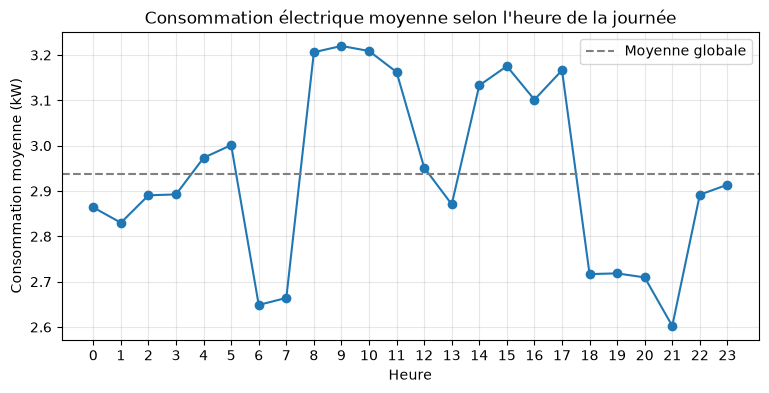

Consommation moyenne par période :
periode
après-midi    3.14
matin         3.02
midi          2.91
nuit          2.89
soir          2.78
Name: power_kw, dtype: float64

Consommation moyenne semaine (Faux) / fin de semaine (Vrai) :
is_weekend
False    3.03
True     2.70
Name: power_kw, dtype: float64


In [37]:
# Visualisation 1
df["hour"] = pd.to_datetime(df["timestamp"]).dt.hour
conso_par_heure = df.groupby("hour")["power_kw"].mean()

plt.figure(figsize=(9, 4))
plt.plot(conso_par_heure.index, conso_par_heure.values, marker="o")
plt.axhline(df["power_kw"].mean(), color="gray", linestyle="--", label="Moyenne globale")
plt.title("Consommation électrique moyenne selon l'heure de la journée")
plt.xlabel("Heure")
plt.ylabel("Consommation moyenne (kW)")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# Périodes de la journée
def periode(heure):
    if 5 <= heure <= 11:
        return "matin"
    elif 12 <= heure <= 13:
        return "midi"
    elif 14 <= heure <= 16:
        return "après-midi"
    elif 17 <= heure <= 21:
        return "soir"
    else:
        return "nuit"

df["periode"] = df["hour"].apply(periode)
print("Consommation moyenne par période :")
print(df.groupby("periode")["power_kw"].mean().sort_values(ascending=False).round(2))

print("\nConsommation moyenne semaine (Faux) / fin de semaine (Vrai) :")
print(df.groupby("is_weekend")["power_kw"].mean().round(2))


### Interprétation

La consommation est la plus forte de 8h à 11h et de 14h à 17h, ce qui correspond aux heures de cours. Elle baisse vers 13h et surtout le soir, de 18h à 21h. Le résultat le plus surprenant est la nuit 22h à 5h : la consommation remonte à environ 2.9 kW, ce qui est presque égal à la moyenne de la journée.

## 12.2 Visualisation 2 : Comparaison entre catégories

**Question analysée :** Quel bâtiment présente la plus forte consommation moyenne?

**Pourquoi ce graphique est-il approprié ?** Le diagramme à barres sert à comparer la consommation moyenne (kW) à la moyenne consommation électrique par bâtiment. L'axe commence à 0, donc la hauteur des barres est directement proportionnelle à la consommation.


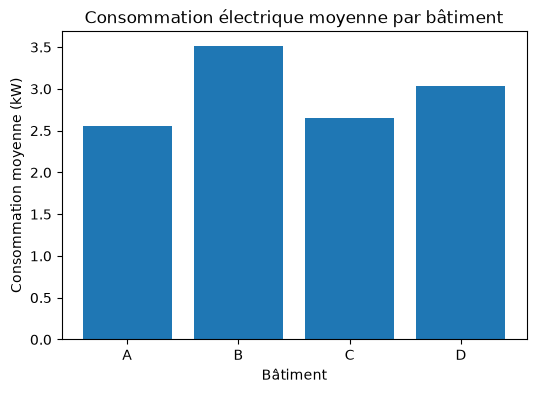

building
A    2.56
B    3.51
C    2.65
D    3.04
Name: power_kw, dtype: float64


In [38]:
# Visualisation 2
conso_par_batiment = df.groupby("building")["power_kw"].mean()

plt.figure(figsize=(6, 4))
plt.bar(conso_par_batiment.index, conso_par_batiment.values)
plt.title("Consommation électrique moyenne par bâtiment")
plt.xlabel("Bâtiment")
plt.ylabel("Consommation moyenne (kW)")
plt.show()

print(conso_par_batiment.round(2))


### Interprétation

Le batiment B consomme le plus de kW parmi les batiments.

## 12.3 Visualisation 3 : Distribution

**Question analysée :** Comment se répartissent les valeurs de consommation électrique ?

**Pourquoi ce graphique est-il approprié ?** L'histogramme montre combien d'observations tombent dans chaque intervalle de consommation, ce qui permet de voir la forme de la distribution. 

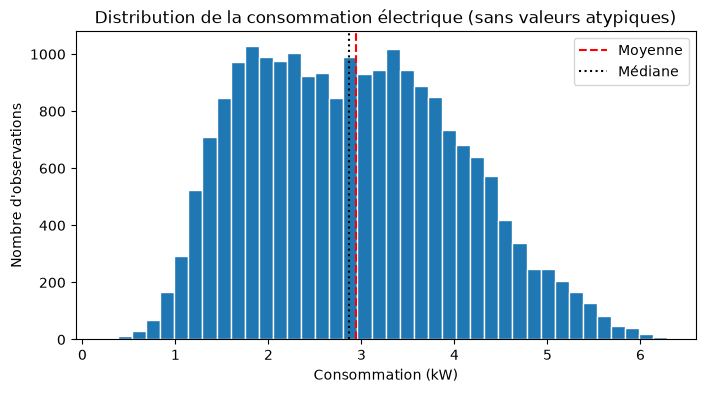

In [39]:
# Visualisation 3
q1, q3 = df["power_kw"].quantile([0.25, 0.75])
borne_sup_power = q3 + 1.5 * (q3 - q1)
power_sans_atypiques = df.loc[df["power_kw"] <= borne_sup_power, "power_kw"]

plt.figure(figsize=(8, 4))
plt.hist(power_sans_atypiques, bins=40, edgecolor="white")
plt.axvline(df["power_kw"].mean(), color="red", linestyle="--", label="Moyenne")
plt.axvline(df["power_kw"].median(), color="black", linestyle=":", label="Médiane")
plt.title("Distribution de la consommation électrique (sans valeurs atypiques)")
plt.xlabel("Consommation (kW)")
plt.ylabel("Nombre d'observations")
plt.legend()
plt.show()


### Interprétation

La plupart des mesures se situent entre 1 et 5 kW. La moyenne (2.94 kW) et la médiane (2.87 kW) sont presque identiques, donc la distribution est à peu près symétrique une fois les pics retirés

## 12.4 Visualisation 4 : Relation entre deux variables

**Question analysée :** Existe-t-il une relation entre l'occupation et la consommation ?

**Pourquoi ce graphique est-il approprié ?** Le nuage de points montre chaque mesure selon deux variables numériques, ce qui permet de voir s'il y a une tendance. Les données utilisées sont celles de `df_valid`.


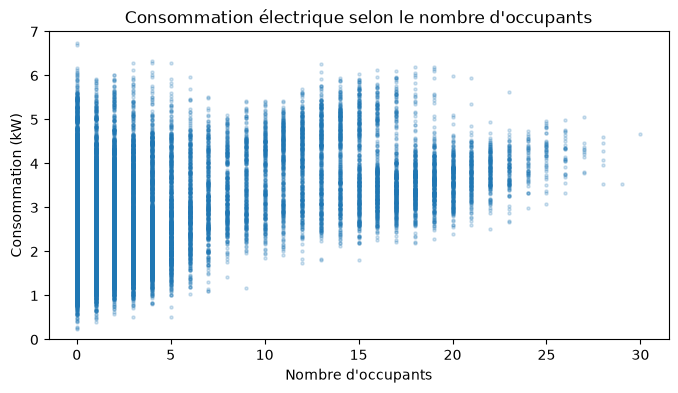

Corrélation : 0.37


In [40]:
# Visualisation 4
df_valid = df[df["occupancy"] <= df["capacity"]]

plt.figure(figsize=(8, 4))
plt.scatter(df_valid["occupancy"], df_valid["power_kw"], s=5, alpha=0.2)
plt.title("Consommation électrique selon le nombre d'occupants")
plt.xlabel("Nombre d'occupants")
plt.ylabel("Consommation (kW)")
plt.ylim(0, 7)
plt.show()

print("Corrélation :", round(df_valid["occupancy"].corr(df_valid["power_kw"]), 2))


### Interprétation

On voit une légère tendance à la hausse : avec plus de 15 occupants, les consommations très faibles (< 1 kW) deviennent rares. La relation reste toutefois faible à modérée (r = 0.37), car pour un même nombre d'occupants, la consommation varie énormément (de 0.5 à 6 kW). Surtout, la colonne à 0 occupant couvre presque toute la plage de consommation : beaucoup de locaux vides consomment autant que des locaux occupés.

## 12.5 Visualisation 5 : Analyse libre

**Question analysée :** Les locaux consomment-ils beaucoup moins lorsqu'ils sont vides?

**Pourquoi ce graphique est-il approprié ?** Les barres groupées placent côte à côte la consommation « occupé » et « vide » pour chaque type de local pour comparer les deux.


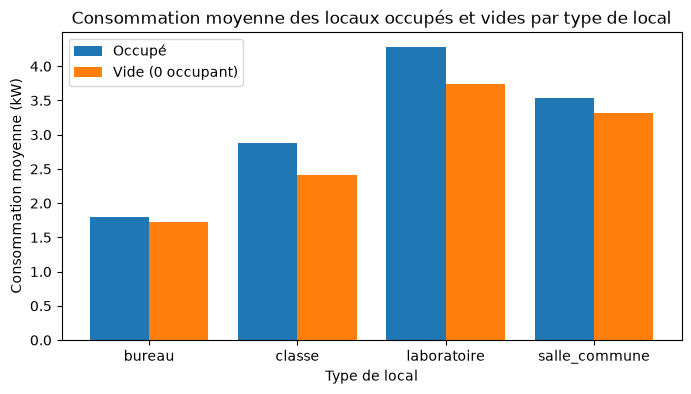

local_vide     False  True  ratio_vide_occupe_%
room_type                                      
bureau          1.79  1.73                96.24
classe          2.88  2.42                84.08
laboratoire     4.29  3.75                87.42
salle_commune   3.54  3.32                93.78


In [41]:
# Visualisation 5
df["local_vide"] = df["occupancy"] == 0
vide_vs_occupe = df.groupby(["room_type", "local_vide"])["power_kw"].mean().unstack()

types = vide_vs_occupe.index
x = np.arange(len(types))
largeur = 0.4

plt.figure(figsize=(8, 4))
plt.bar(x - largeur / 2, vide_vs_occupe[False], width=largeur, label="Occupé")
plt.bar(x + largeur / 2, vide_vs_occupe[True], width=largeur, label="Vide (0 occupant)")
plt.xticks(x, types)
plt.title("Consommation moyenne des locaux occupés et vides par type de local")
plt.xlabel("Type de local")
plt.ylabel("Consommation moyenne (kW)")
plt.legend()
plt.show()

vide_vs_occupe["ratio_vide_occupe_%"] = vide_vs_occupe[True] / vide_vs_occupe[False] * 100
print(vide_vs_occupe.round(2))


### Interprétation

Pour tous les types de locaux, la consommation d'un local vide reste très proche de celle d'un local occupé. Un bureau vide consomme 96% de ce qu'il consomme occupé, une salle commune 94%, un laboratoire 87% et une classe 84%. Le fait de vider un local ne réduit donc presque pas sa consommation. Cela suggère que le chauffage, la ventilation et l'éclairage fonctionnent selon un horaire fixe plutôt que selon la présence réelle.

## 12.6 Visualisation 6 : Analyse libre

**Question analysée :** Quels locaux consomment le plus lorsqu'ils sont vides ?

**Pourquoi ce graphique est-il approprié ?** Un diagramme à barres horizontales trié permet de classer les 16 locaux et de lire facilement leurs noms. Le local le plus problématique apparaît en haut.


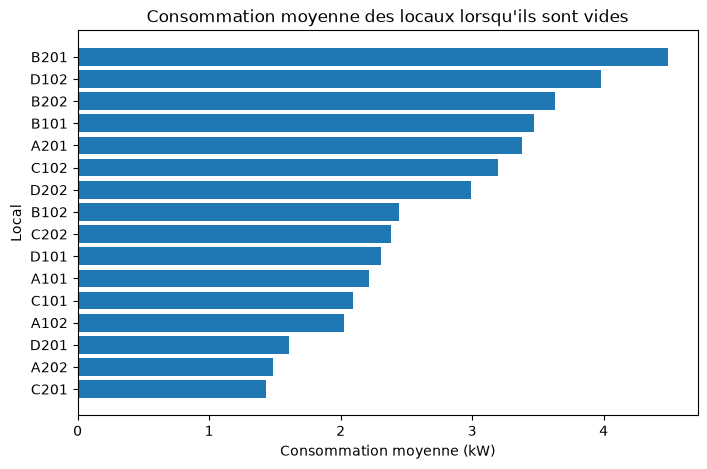

In [42]:
# Visualisation 6
conso_vide_par_local = df[df["occupancy"] == 0].groupby("room")["power_kw"].mean().sort_values()

plt.figure(figsize=(8, 5))
plt.barh(conso_vide_par_local.index, conso_vide_par_local.values)
plt.title("Consommation moyenne des locaux lorsqu'ils sont vides")
plt.xlabel("Consommation moyenne (kW)")
plt.ylabel("Local")
plt.show()

### Interprétation

 Le laboratoire B201 et le laboratoire D102 sont les locaux qui consomment le plus lorsqu'il n'y a personne, suivis de la salle commune B202 et de la classe B101. Trois de ces quatre locaux sont dans le batiment B. Au total, les locaux sont vides dans 31 % des mesures, et ces moments représentent 27.7 % de toute l'énergie consommée. C'est une part importante qui pourrait être réduite.

# 13. Visualisations interactives

Au moins **2 visualisations** doivent être interactives.

Utilisez `ipywidgets.interact` afin de permettre à l'utilisateur d'explorer les données selon un ou plusieurs critères.

Exemples de paramètres :

- bâtiment ;
- local ;
- jour ;
- période ;
- variable ;
- seuil.

L'interactivité doit avoir une **utilité analytique réelle**.


## 13.1 Visualisation interactive 1

Expliquez :

- ce que l'utilisateur peut sélectionner ;
   - Le batiment (Tous,A,B,C ou D)
   - Le type de jour (tous, semaine ou fin de semaine)
- pourquoi cette interaction est utile.
   - Pour voir la consommation en moyenne dans la semaine ou la fin de semaine. On peut voir ou les bâtiments consomment plus ou moins dans la durée de la journée.



In [43]:
# Visualisation interactive 1

def consommation_par_heure(batiment="Tous", type_jour="Tous"):
    donnees = df
    if batiment != "Tous":
        donnees = donnees[donnees["building"] == batiment]
    if type_jour == "Semaine":
        donnees = donnees[donnees["is_weekend"] == False]
    elif type_jour == "Fin de semaine":
        donnees = donnees[donnees["is_weekend"] == True]

    conso_heure = donnees.groupby("hour")["power_kw"].mean()

    plt.figure(figsize=(10, 5))
    plt.plot(conso_heure.index, conso_heure.values, marker="o")
    plt.title(f"Consommation moyenne par heure - bâtiment : {batiment}, jours : {type_jour}")
    plt.xlabel("Heure de la journée")
    plt.ylabel("Consommation moyenne (kW)")
    plt.xticks(range(0, 24))
    plt.grid(alpha=0.3)
    plt.show()


interact(
    consommation_par_heure,
    batiment=["Tous", "A", "B", "C", "D"],
    type_jour=["Tous", "Semaine", "Fin de semaine"],
)

interactive(children=(Dropdown(description='batiment', options=('Tous', 'A', 'B', 'C', 'D'), value='Tous'), Dr…

<function __main__.consommation_par_heure(batiment='Tous', type_jour='Tous')>

## 13.2 Visualisation interactive 2

Expliquez :

- ce que l'utilisateur peut sélectionner ;
   - Les batiments A,B,C ou D
   - Les nombres de maximum d'occupants (0-10).
- pourquoi cette interaction est utile.
   - Pour savoir quels locaux consomment beaucoup ou pas en fonction de son occupation.


In [44]:
# Visualisation interactive 2

def consommation_locaux_peu_occupes(batiment="Tous", max_occupants=0):
    donnees = df[df["occupancy"] <= max_occupants]
    if batiment != "Tous":
        donnees = donnees[donnees["building"] == batiment]

    conso_local = donnees.groupby("room")["power_kw"].mean().sort_values(ascending=False)

    plt.figure(figsize=(10, 5))
    plt.bar(conso_local.index, conso_local.values)
    plt.title(f"Consommation moyenne des locaux avec {max_occupants} occupant(s) ou moins - bâtiment : {batiment}")
    plt.xlabel("Local")
    plt.ylabel("Consommation moyenne (kW)")
    plt.grid(alpha=0.3, axis="y")
    plt.show()


interact(
    consommation_locaux_peu_occupes,
    batiment=["Tous", "A", "B", "C", "D"],
    max_occupants=(0, 10, 1),
)

interactive(children=(Dropdown(description='batiment', options=('Tous', 'A', 'B', 'C', 'D'), value='Tous'), In…

<function __main__.consommation_locaux_peu_occupes(batiment='Tous', max_occupants=0)>

# 14. Questions d'analyse

Répondez au minimum aux questions suivantes :

1. Quel bâtiment présente la plus forte consommation moyenne ?
2. Quels locaux présentent la plus forte variabilité ?
3. À quelles périodes observe-t-on les consommations les plus importantes ?
4. Existe-t-il une relation entre l'occupation et la consommation ?
5. Quelles observations semblent atypiques ?
6. Quel constat semble le plus important pour l'organisation ?

Ajoutez ensuite **au moins 2 questions supplémentaires** proposées par l'équipe.


1. Le bâtiment B consomme plus que bâtiment A,C et D.
2. Les locaux D102, C201 et B101
3. Pendant les heures de 8h à 11h et de 14h à 17h, sont les plus élevés. La consommation est aussi plus élevée en semaine que la fin de semaine. Puis, la nuit consomme presque autant que la moyenne de la journée malgré que les classes ne sont pas occupées.
4. Relation légère, lorsqu’il n'y a pas d'occupants,  la consommation reste quand même élevée.
5. Avec la méthode IQR le kW monte jusqu'à  27.91 W, ce qui n'est pas normal quand comparer à la moyenne de 2,94 kW.
6. Les locaux consomment presque autant quand ils sont vides que quand ils sont occupés. Le bâtiment B est le plus touché : c'est le bâtiment qui consomme le plus puisque 3 des 4 locaux qui consomment le plus lorsqu'ils sont vides s'y trouvent (B201, B202 et B101).

# 15. Synthèse

Présentez les principaux constats de l'analyse.

Votre synthèse doit relier les résultats statistiques, les visualisations et les questions étudiées.

### Notre synthèse

Notre problématique était : *comment réduire la consommation énergétique inutile dans les bâtiments ?*

- Les statistiques descriptives montrent une consommation moyenne de 2,94 kW par local et une médiane de 2,87 kW. Elles montrent aussi que beaucoup de mesures ont une occupation de 0.
- Les groupby et la visualisation 12.1 montrent que la consommation est plus forte pendant les heures de cours (8 h - 11 h et 14 h - 17 h), mais qu'elle reste élevée la nuit (environ 2,9 kW) alors que les locaux sont presque vides.
- La visualisation 12.2 montre que le bâtiment B consomme le plus (3,51 kW).
- La corrélation (0,37) et la visualisation 12.4 montrent que l'occupation n'explique qu'une petite partie de la consommation.
- Les visualisations 12.5 et 12.6 répondent à nos questions d'analyse : un local vide consomme encore 84% à 96% de sa consommation normale, et les locaux vides représentent 27,7 % de l'énergie totale. Les locaux qui consomment le plus à vide sont B201, D102, B202 et B101.
- Les valeurs atypiques sont rares (36 mesures de consommation) et ressemblent surtout à des erreurs de capteur.

En résumé, une grande partie de l'énergie est consommée sans que personne est présent, surtout la nuit, la fin de semaine et dans le bâtiment B.


# 16. Recommandations

Formulez au moins **une recommandation** destinée à l'organisation.

La recommandation doit être appuyée par les données et les analyses réalisées.

### Nos recommandations

**Recommandation principale : réduire la consommation des locaux vides, en commençant par le bâtiment B.**

Les données montrent qu'un local vide consomme presque autant qu'un local occupé (84 % à 96 %) et que les locaux vides représentent 27,7 % de l'énergie totale. L'organisation pourrait :

1. **Réduire le chauffage et la ventilation la nuit et la fin de semaine**, car la consommation de nuit (2,89 kW) est presque égale à la moyenne de la journée.
2. **Commencer par le bâtiment B** (le plus énergivore, 3,51 kW) et par les locaux B201, B202, B101 et D102, qui consomment le plus lorsqu'ils sont vides.


# 17. Conclusion

Présentez :

- trois constats importants ;
- une recommandation principale ;
- une analyse supplémentaire qui pourrait être effectuée si davantage de données étaient disponibles.

### Notre conclusion

**Trois constats importants :**
1. Le **bâtiment B** a la plus forte consommation moyenne (3,51 kW).
2. Les **locaux vides consomment presque autant que les locaux occupés** : ils représentent 27,7 % de l'énergie totale.
3. La consommation **reste élevée la nuit** (environ 2,9 kW), alors que les locaux sont presque vides.

# Répartition finale des contributions

| Membre | Contributions réalisées |
|---|---|
| Étudiant(e) 1 | Détection des valeurs atypiques (IQR), matrice de corrélation, 6 graphiques et 2 graphiques interactifs, réponses aux questions, synthèse, recommandations et conclusion |
| Étudiant(e) 2 |  |
| Étudiant(e) 3 | Presentation du probleme, Statistiques descriptives, Analyses par groupe,  Filtrage des données|

> Tous les membres doivent être capables d'expliquer la démarche générale du projet.


# Consigne importante pour la remise

Le notebook remis doit être **exécuté avant la remise** et doit conserver toutes les sorties générées.

Le fichier `.ipynb` remis doit donc contenir directement :

- les aperçus de données affichés ;
- les tableaux de résultats ;
- les statistiques calculées ;
- les résultats des filtres et des regroupements ;
- les valeurs atypiques détectées ;
- les matrices ou coefficients de corrélation ;
- les graphiques statiques ;
- les visualisations interactives configurées dans le notebook ;
- toute autre sortie nécessaire à la compréhension de l'analyse.

> **Ne remettez pas un notebook dont les cellules ont été vidées de leurs sorties.**

Avant la remise, utilisez :

**Kernel / Restart & Run All**  
ou l'équivalent dans votre environnement Jupyter,

puis vérifiez que le notebook s'exécute **du début à la fin sans erreur** et que les résultats demeurent visibles dans le fichier enregistré.


## Grille d'évaluation

| Partie | Points |
|---|---:|
| Compréhension du jeu de données | 5 |
| Nettoyage et préparation | 10 |
| Création de nouvelles variables | 8 |
| Statistiques descriptives | 10 |
| Filtrage et agrégations | 8 |
| Valeurs atypiques | 8 |
| Corrélation | 6 |
| Visualisations | 20 |
| Interprétation | 15 |
| Conclusion | 5 |
| Qualité du notebook | 5 |
| **Total** | **100** |

---

## Vérification avant la remise

- [ ] Les noms, prénoms et numéros DA sont inscrits.
- [ ] Le notebook s'exécute du début à la fin sans erreur.
- [ ] Toutes les cellules nécessaires ont été exécutées avant l'enregistrement final.
- [ ] Les sorties, résultats, tableaux et graphiques sont visibles dans le notebook remis.
- [ ] Les valeurs manquantes et doublons ont été analysés.
- [ ] Au moins 3 nouvelles variables ont été créées.
- [ ] Au moins 3 filtres booléens sont présents.
- [ ] Au moins 2 `groupby()` sont utilisés.
- [ ] Les statistiques descriptives sont interprétées.
- [ ] Les valeurs atypiques sont analysées.
- [ ] Les corrélations sont interprétées.
- [ ] Au moins 6 visualisations sont présentes.
- [ ] Au moins 2 visualisations sont interactives.
- [ ] Chaque graphique possède un titre et des axes appropriés.
- [ ] Chaque graphique est justifié et interprété.
- [ ] La synthèse et la conclusion sont complètes.
- [ ] La répartition finale des contributions est indiquée.
